# ASL Fingerspelling Model

## 1. Setup

In [1]:
# %pip install torch torchvision torchaudio scikit-learn matplotlib pillow kagglehub chatterbox-tts
import json, random
from collections import Counter
from pathlib import Path

import torchaudio as ta
from chatterbox.tts import ChatterboxTTS

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ---- Settings you may want to change (all in one place) ----
SEED       = 42
IMG_SIZE   = 64      # images are resized to IMG_SIZE x IMG_SIZE. Lower = faster on CPU (try 48 or 32 if slow)
BATCH_SIZE = 32
EPOCHS     = 30
LR         = 1e-3
DATA_DIR   = "./asl_dataset/"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Training on:", device)

/mnt/d/Deep Learning/DeepLearning_ASL_Final/.venv/lib/python3.12/site-packages/perth/perth_net/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename
/mnt/d/Deep Learning/DeepLearning_ASL_Final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training on: cuda


## 2. Load the dataset

The Kaggle dataset stores one folder per class (`0`...`9`, `a`...`z`), and the folder name is the label. We build a list of image paths and labels from the folder structure rather than loading every image right away.

In [2]:
print("Data folder:", DATA_DIR)

VALID_LABELS = set("0123456789abcdefghijklmnopqrstuvwxyz")
IMG_EXTS = {".jpg", ".jpeg", ".png"}

paths, labels = [], []
for p in sorted(Path(DATA_DIR).rglob("*")):
    if p.suffix.lower() in IMG_EXTS and p.parent.name.lower() in VALID_LABELS:
        paths.append(p)
        labels.append(p.parent.name.lower())

classes = sorted(set(labels))               # '0'..'9','a'..'z'
class_to_idx = {c: i for i, c in enumerate(classes)}
y_all = np.array([class_to_idx[l] for l in labels])

print(f"Total images: {len(paths)}")
print(f"Number of classes: {len(classes)}  ->  {classes}")
assert len(classes) == 36, "Expected 36 classes. Check the folder structure of DATA_DIR."

Data folder: ./asl_dataset/
Total images: 5030
Number of classes: 36  ->  ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


## 3. Explore the data (Step 1, exploratory analysis)

Things we want to know before modeling: is it balanced, what size are the raw images, and what do the classes look like (especially the ones that might be confusable)?

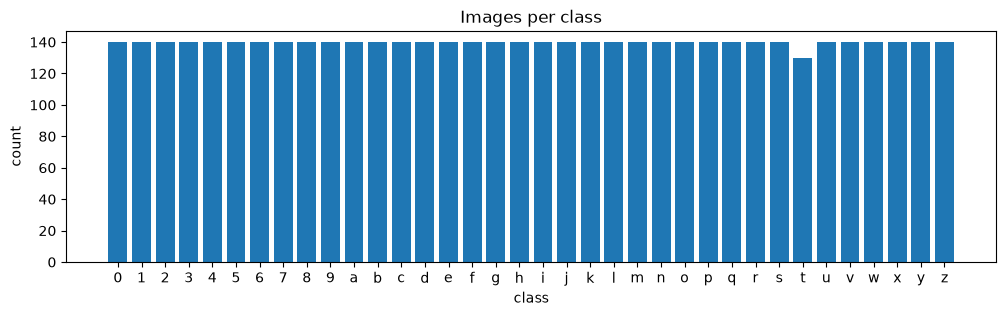

min / max images per class: 130 / 140
Raw image sizes (width, height) -> count: {(400, 400): 5030}


In [3]:
counts = Counter(labels)
plt.figure(figsize=(12, 3))
plt.bar(classes, [counts[c] for c in classes])
plt.title("Images per class"); plt.xlabel("class"); plt.ylabel("count")
plt.show()
print("min / max images per class:", min(counts.values()), "/", max(counts.values()))

sizes = Counter(Image.open(p).size for p in paths)
print("Raw image sizes (width, height) -> count:", dict(sizes.most_common(5)))

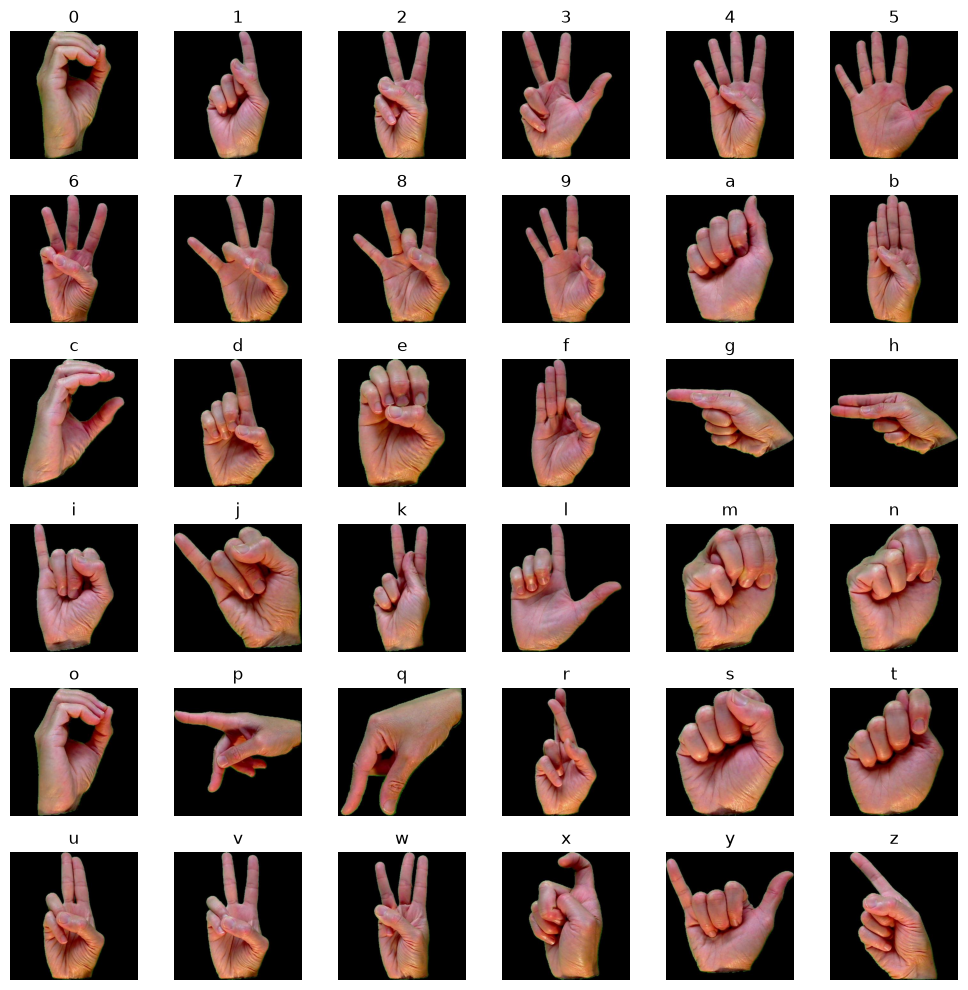

In [4]:
# One example per class
fig, axes = plt.subplots(6, 6, figsize=(10, 10))
for ax, c in zip(axes.ravel(), classes):
    p = next(p for p, l in zip(paths, labels) if l == c)
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

**Look for this in the grid:** a few classes are visually near-identical as hand shapes (for example `0` vs `o`, `2` vs `v`, `6` vs `w`). Expect the CNN to confuse these. That is a property of the signs, not necessarily a bug, and we will check it in the error analysis.

## 4. Train / validation / test split

A **stratified** 70 / 15 / 15 split keeps every class represented in each set. We split *once*, up front, with a fixed seed, so the test set stays untouched until the final evaluation.

- **Train**: the model learns from these.
- **Validation**: we use it during training to choose the best epoch and tune settings.
- **Test**: used once at the end for an honest estimate of performance.

In [5]:
idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=y_all[temp_idx], random_state=SEED)

print(f"train: {len(train_idx)}   val: {len(val_idx)}   test: {len(test_idx)}")

train: 3521   val: 754   test: 755


## 5. Preprocessing

1. **Resize** every image to `IMG_SIZE x IMG_SIZE` and convert to RGB. A smaller image means fewer pixels, so faster training.
2. **Scale to [0, 1]**, then **normalize** each color channel using the *training set's* mean and standard deviation. Normalizing roughly centers the inputs at 0 with similar spread, which makes gradient descent behave better.

We load the resized images into memory once (the dataset is small), so training doesn't re-read files from disk every epoch. We compute the normalization statistics from the **training images only** so no information from validation/test leaks in.

In [6]:
def load_resized(index_list):
    arr = np.zeros((len(index_list), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for k, i in enumerate(index_list):
        arr[k] = np.array(Image.open(paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    return arr

X_train, y_train = load_resized(train_idx), y_all[train_idx]
X_val,   y_val   = load_resized(val_idx),   y_all[val_idx]
X_test,  y_test  = load_resized(test_idx),  y_all[test_idx]

mean = (X_train / 255.0).mean(axis=(0, 1, 2))
std  = (X_train / 255.0).std(axis=(0, 1, 2))
print("channel mean:", mean.round(3), " channel std:", std.round(3))

channel mean: [0.223 0.154 0.139]  channel std: [0.298 0.216 0.205]


## 6. Augmentation and data loaders

The dataset is small (about 70 images per class), so the model can easily **memorize** the training images. Augmentation shows the model slightly different versions of each image every epoch, which pushes it to learn the hand shape instead of memorizing exact pixels.

We only augment the training set. Validation and test images get only resize + normalize.

Note that we aren't flipping images. Flipping turns a right hand into a left hand, which isn't what the signs in the data look like.

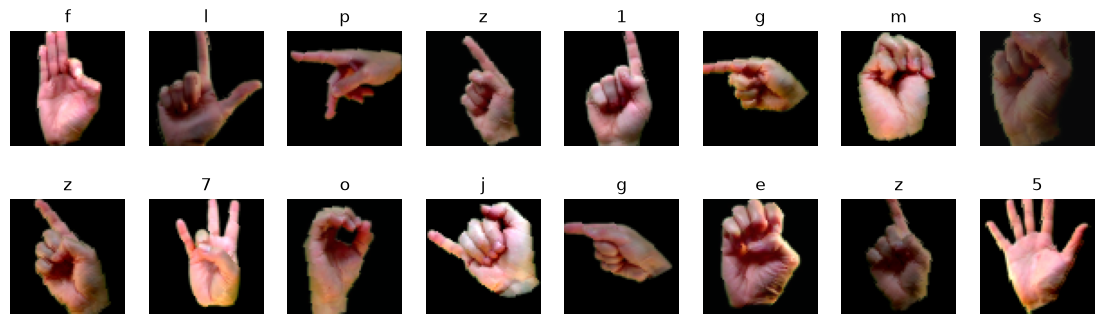

In [7]:
train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class ASLDataset(Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.tf(self.X[i]), int(self.y[i])

train_loader = DataLoader(ASLDataset(X_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(ASLDataset(X_val,   y_val,   eval_tf),  batch_size=BATCH_SIZE)
test_loader  = DataLoader(ASLDataset(X_test,  y_test,  eval_tf),  batch_size=BATCH_SIZE)

# Sanity check: what the model actually sees (augmented training images)
xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lab in zip(axes.ravel(), xb[:16], yb[:16]):
    img = (img.permute(1, 2, 0).numpy() * std + mean).clip(0, 1)   # undo normalization for display
    ax.imshow(img); ax.set_title(classes[lab]); ax.axis("off")
plt.show()

## 7. The model: a baseline CNN

Three convolution blocks, then a small classifier head.

- `Conv2d`: slides small 3x3 filters across the image. Early filters pick up edges, later ones combine them into finger and hand shapes.
- `BatchNorm2d`: keeps the numbers flowing through the network well-scaled, which helps training.
- `ReLU`: the non-linearity (without it, stacked layers would collapse into one linear operation).
- `MaxPool2d`: shrinks the image by half, keeping the strongest responses, so deeper layers see a bigger area of the hand.
- `AdaptiveAvgPool2d(4)`: forces the feature map to a fixed 4x4 so the model works for any `IMG_SIZE`.
- `Dropout`: randomly switches off units during training so the network can't over-rely on any one of them.
- Final `Linear` outputs **36 scores** (one per class). The loss function turns these into probabilities.

This is intentionally small: it is a baseline to beat, and it trains on a CPU.

In [8]:
class ASLNet(nn.Module):
    def __init__(self, n_classes=36):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(4))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = ASLNet(len(classes)).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# Shape check with a fake batch: should print torch.Size([2, 36])
print(model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)

ASLNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): AdaptiveAvgPool2d(output_size=4)
  )
  (classifier): Sequen

## 8. Training

- **Loss:** `CrossEntropyLoss` is the standard loss for multi-class classification. It is small when the model puts high probability on the correct class.
- **Optimizer:** Adam.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct    += (logits.argmax(1) == yb).sum().item()
            n          += len(yb)
    return total_loss / n, correct / n

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, BEST_PATH = 0.0, "asl_cnn_best.pt"

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), BEST_PATH)
    print(f"epoch {epoch:02d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

print("Best validation accuracy:", round(best_val_acc, 3))

epoch 01 | train loss 2.504 acc 0.284 | val loss 0.944 acc 0.763
epoch 02 | train loss 1.222 acc 0.579 | val loss 0.527 acc 0.865
epoch 03 | train loss 0.856 acc 0.700 | val loss 0.355 acc 0.924
epoch 04 | train loss 0.683 acc 0.750 | val loss 0.263 acc 0.932
epoch 05 | train loss 0.588 acc 0.784 | val loss 0.208 acc 0.923
epoch 06 | train loss 0.515 acc 0.813 | val loss 0.185 acc 0.942
epoch 07 | train loss 0.513 acc 0.813 | val loss 0.175 acc 0.944
epoch 08 | train loss 0.447 acc 0.839 | val loss 0.173 acc 0.932
epoch 09 | train loss 0.446 acc 0.836 | val loss 0.171 acc 0.935
epoch 10 | train loss 0.389 acc 0.850 | val loss 0.140 acc 0.944
epoch 11 | train loss 0.405 acc 0.853 | val loss 0.136 acc 0.944
epoch 12 | train loss 0.376 acc 0.857 | val loss 0.173 acc 0.922
epoch 13 | train loss 0.327 acc 0.875 | val loss 0.108 acc 0.955
epoch 14 | train loss 0.316 acc 0.878 | val loss 0.098 acc 0.968
epoch 15 | train loss 0.315 acc 0.878 | val loss 0.119 acc 0.948
epoch 16 | train loss 0.2

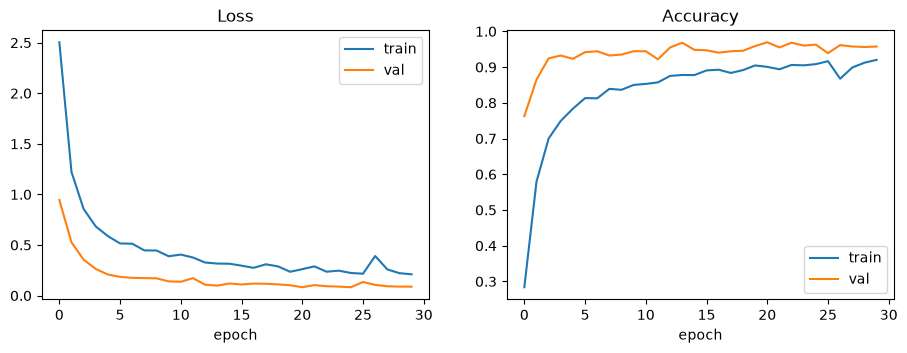

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(history["train_loss"], label="train"); a1.plot(history["val_loss"], label="val"); a1.set_title("Loss"); a1.legend()
a2.plot(history["train_acc"],  label="train"); a2.plot(history["val_acc"],  label="val"); a2.set_title("Accuracy"); a2.legend()
for a in (a1, a2): a.set_xlabel("epoch")
plt.show()

## 9. Final evaluation on the test set

We load the best-validation weights and run the test set once. Everything here is raw character-level accuracy.

In [11]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        all_preds.append(model(xb.to(device)).argmax(1).cpu().numpy())
        all_true.append(yb.numpy())
all_preds, all_true = np.concatenate(all_preds), np.concatenate(all_true)

print(f"Test accuracy: {(all_preds == all_true).mean():.3f}   ({len(all_true)} images)\n")
print(classification_report(all_true, all_preds, labels=range(len(classes)), target_names=classes, zero_division=0))

Test accuracy: 0.959   (755 images)

              precision    recall  f1-score   support

           0       0.90      0.43      0.58        21
           1       1.00      0.95      0.98        21
           2       0.91      1.00      0.95        21
           3       1.00      1.00      1.00        21
           4       0.91      0.95      0.93        21
           5       0.95      0.90      0.93        21
           6       0.69      0.95      0.80        21
           7       1.00      1.00      1.00        21
           8       1.00      1.00      1.00        21
           9       1.00      1.00      1.00        21
           a       1.00      0.90      0.95        21
           b       1.00      1.00      1.00        21
           c       1.00      1.00      1.00        21
           d       1.00      1.00      1.00        21
           e       1.00      1.00      1.00        21
           f       1.00      1.00      1.00        21
           g       1.00      1.00      1.00 

## 10. Error analysis

Which characters get mixed up? With only ~10 test images per class, treat per-class numbers as rough, but patterns in the confusion matrix are still informative.

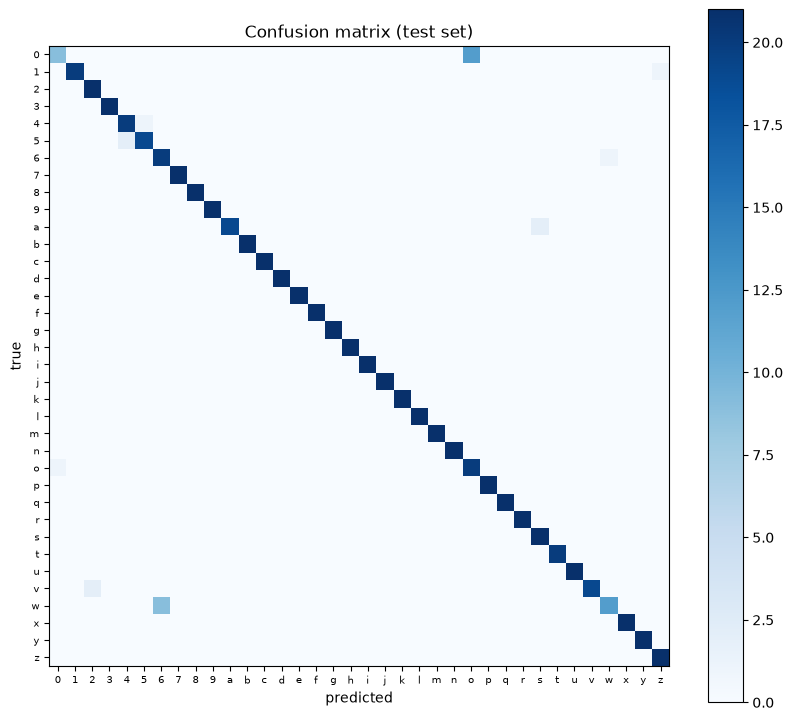

Most common confusions (true -> predicted, count):
  0 -> o: 12
  w -> 6: 9
  5 -> 4: 2
  a -> s: 2
  v -> 2: 2
  1 -> z: 1
  4 -> 5: 1
  6 -> w: 1
  o -> 0: 1


In [12]:
cm = confusion_matrix(all_true, all_preds, labels=range(len(classes)))

plt.figure(figsize=(10, 9))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(classes)), classes, fontsize=7); plt.yticks(range(len(classes)), classes, fontsize=7)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (test set)"); plt.colorbar()
plt.show()

# Most common mistakes
mistakes = [(classes[t], classes[p], cm[t, p]) for t in range(len(classes)) for p in range(len(classes)) if t != p and cm[t, p] > 0]
mistakes.sort(key=lambda m: -m[2])
print("Most common confusions (true -> predicted, count):")
for t, p, c in mistakes[:10]:
    print(f"  {t} -> {p}: {c}")

## 11. Save artifacts and a prediction helper

Saving the class list and a `predict_image` function gives Steps 4 and 5 (text-to-speech, live recognition) a clean interface to the model: image in, top predictions with confidence out. Returning the top 3 with probabilities, instead of only the best guess, lets a later text-correction step use confidence, while we keep evaluating the raw classifier separately here.

In [ ]:
with open("asl_classes.json", "w") as f:
    json.dump({"classes": classes, "img_size": IMG_SIZE, "mean": mean.tolist(), "std": std.tolist()}, f)

def predict_image(path, top_k=3):
    """Return the top_k (character, probability) guesses for one image file."""
    img = np.array(Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    x = eval_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    top = probs.topk(top_k)
    return [(classes[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

print(predict_image(paths[test_idx[0]]), "| true:", classes[y_test[0]])

[('c', 1.0), ('o', 0.0), ('l', 0.0)] | true: c


## Next steps

- [ ] **Step 3:** try changes one at a time and compare on the *validation* set: a deeper network, `IMG_SIZE` 32 / 64 / 96, stronger or weaker augmentation, learning rate, transfer learning from a pretrained model (e.g. ResNet18).
- [ ] **Step 3:** if `0`/`o`, `2`/`v`, `6`/`w` stay confused, decide how to handle them (merge classes, or let the later text step use context to choose).
- [ ] **Step 3:** test robustness: evaluate on a few photos we take ourselves (different lighting, background, hand) to see how much accuracy drops outside the dataset.
- [ ] **Step 4:** feed `predict_image` output into the text-to-speech step.
- [ ] **Step 5:** real-time recognition from webcam frames using the same preprocessing.

In [ ]:
voice_model = ChatterboxTTS.from_pretrained(device=device)

text = "Ezreal and Jinx teamed up with Ahri, Yasuo, and Teemo to take down the enemy's Nexus in an epic late-game pentakill."
wav = voice_model.generate(text)
ta.save("test-1.wav", wav, voice_model.sr)

/mnt/d/Deep Learning/DeepLearning_ASL_Final/.venv/lib/python3.12/site-packages/diffusers/models/lora.py:393: FutureWarning: `LoRACompatibleLinear` is deprecated and will be removed in version 1.0.0. Use of `LoRACompatibleLinear` is deprecated. Please switch to PEFT backend by installing PEFT: `pip install peft`.
  deprecate("LoRACompatibleLinear", "1.0.0", deprecation_message)


loaded PerthNet (Implicit) at step 250,000


/usr/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
`sdpa` attention does not support `output_attentions=True`. Please set your attention to `eager` if you want any of these features.
Sampling:  14%|█▍        | 143/1000 [00:08<00:51, 16.60it/s]


In [30]:
print(paths)

[PosixPath('asl_dataset/0/hand1_0_bot_seg_1_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_bot_seg_2_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_bot_seg_3_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_bot_seg_4_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_bot_seg_5_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_dif_seg_1_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_dif_seg_2_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_dif_seg_3_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_dif_seg_4_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_dif_seg_5_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_left_seg_1_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_left_seg_2_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_left_seg_3_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_left_seg_4_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_left_seg_5_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_right_seg_1_cropped.jpeg'), PosixPath('asl_dataset/0/hand1_0_right_seg_2_cro

In [33]:
hello_there = [91, 124, 139, 166, 169, -1, 183, 230, 255, 264, 293]

text = ""

for idx in hello_there:
    if idx == -1:
        text += " "
    else:
        print(paths[test_idx[idx]])
        char = predict_image(paths[test_idx[idx]])[0][0]
        text += char
print(text)
wav = voice_model.generate(text)
ta.save("test-1.wav", wav, voice_model.sr)


asl_dataset/asl_dataset/h/hand5_h_bot_seg_5_cropped.jpeg
asl_dataset/asl_dataset/e/hand5_e_dif_seg_2_cropped.jpeg
asl_dataset/l/hand2_l_bot_seg_4_cropped.jpeg
asl_dataset/l/hand2_l_left_seg_5_cropped.jpeg
asl_dataset/asl_dataset/o/hand2_o_left_seg_3_cropped.jpeg
asl_dataset/t/hand4_t_bot_seg_4_cropped.jpeg
asl_dataset/h/hand4_h_bot_seg_1_cropped.jpeg
asl_dataset/asl_dataset/e/hand5_e_bot_seg_4_cropped.jpeg
asl_dataset/r/hand5_r_dif_seg_2_cropped.jpeg
asl_dataset/e/hand2_e_top_seg_1_cropped.jpeg
hello there


Sampling:   2%|▏         | 18/1000 [00:00<00:45, 21.42it/s]
